# Shot Type EDA (Mehrub)

Using NBA shot chart data (`train_with_player_bio.csv`), how do shot action types and three-point indicators relate to shot volume and field goal make percentage?

**Columns:** `ACTION_TYPE`, `IS_THREE`

**Questions:**
- Which shot types go in the most?
- Which rare types should be grouped?
- Is `IS_THREE` just distance?

**Notes:**
- Dropped rows missing `ACTION_TYPE`, `IS_THREE`, or `SHOT_MADE`
- Grouped `ACTION_TYPE` values with fewer than 100 occurrences into `"Other / Rare"` to handle high cardinality
- Checked `SHOT_DISTANCE` vs. `IS_THREE` edge cases (such as corner threes)

In [3]:
import pandas as pd

crunch_table = pd.read_csv('datasets/train_with_player_bio.csv')

columns = crunch_table.columns.tolist()

missing_action = crunch_table['ACTION_TYPE'].isnull().sum()
missing_three = crunch_table['IS_THREE'].isnull().sum()

crunch_table = crunch_table.dropna(subset=['ACTION_TYPE', 'IS_THREE', 'SHOT_MADE'])

frequency_tally = crunch_table['ACTION_TYPE'].value_counts()
rare_bucket = frequency_tally[frequency_tally < 100].index

crunch_table['ACTION_TYPE_CLEANED'] = crunch_table['ACTION_TYPE'].apply(lambda x: 'Other / Rare' if x in rare_bucket else x)

unique_before = crunch_table['ACTION_TYPE'].nunique()
unique_after = crunch_table['ACTION_TYPE_CLEANED'].nunique()

mismatch_bucket = crunch_table[((crunch_table['SHOT_DISTANCE'] >= 24) & (crunch_table['IS_THREE'] == 0)) | 
                                ((crunch_table['SHOT_DISTANCE'] < 22) & (crunch_table['IS_THREE'] == 1))]

## Shot Type Counts and Make Percentage

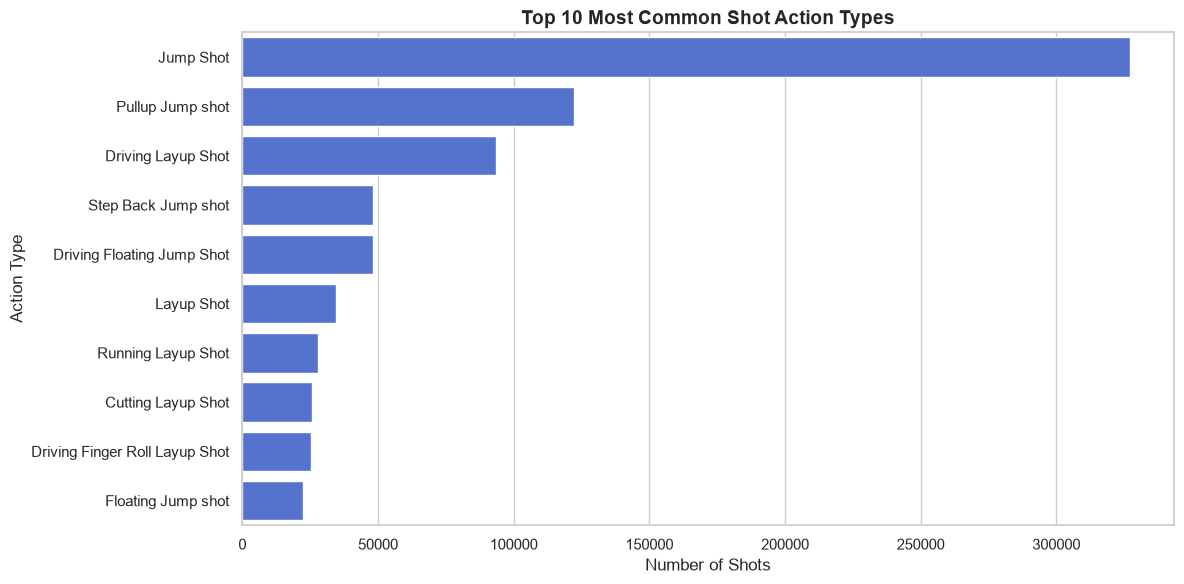

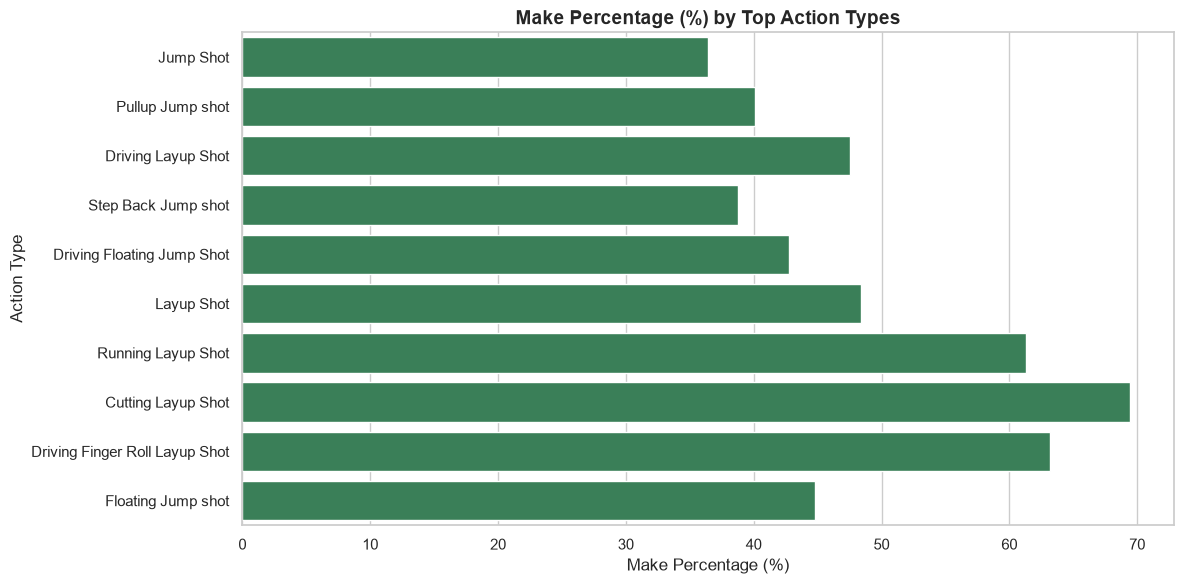

In [4]:
import matplotlib.pyplot as pyplot
import seaborn as seaborn_library

seaborn_library.set_theme(style="whitegrid")

pyplot.figure(figsize=(12, 6))
top_actions = crunch_table['ACTION_TYPE'].value_counts().head(10)
seaborn_library.barplot(x=top_actions.values, y=top_actions.index, color='royalblue')
pyplot.title('Top 10 Most Common Shot Action Types', fontsize=14, fontweight='bold')
pyplot.xlabel('Number of Shots', fontsize=12)
pyplot.ylabel('Action Type', fontsize=12)
pyplot.tight_layout()
pyplot.savefig('shot_type_counts.png')
pyplot.show()

pyplot.figure(figsize=(12, 6))
make_percentage_series = crunch_table.groupby('ACTION_TYPE')['SHOT_MADE'].mean().loc[top_actions.index] * 100
seaborn_library.barplot(x=make_percentage_series.values, y=make_percentage_series.index, color='seagreen')
pyplot.title('Make Percentage (%) by Top Action Types', fontsize=14, fontweight='bold')
pyplot.xlabel('Make Percentage (%)', fontsize=12)
pyplot.ylabel('Action Type', fontsize=12)
pyplot.tight_layout()
pyplot.savefig('shot_type_make_pct.png')
pyplot.show()

In [5]:
stats_ledger = (
    crunch_table.groupby('ACTION_TYPE_CLEANED')
    .agg(
        shot_count=('SHOT_MADE', 'count'),
        make_pct=('SHOT_MADE', lambda x: round(x.mean() * 100, 2)),
        three_pt_pct=('IS_THREE', lambda x: round(x.mean() * 100, 2)),
        avg_distance=('SHOT_DISTANCE', lambda x: round(x.mean(), 1))
    )
    .sort_values('shot_count', ascending=False)
)

print(stats_ledger.head(12))
print("\nTotal rows in Other / Rare:", stats_ledger.loc['Other / Rare', 'shot_count'] if 'Other / Rare' in stats_ledger.index else 0)

                                shot_count  make_pct  three_pt_pct  \
ACTION_TYPE_CLEANED                                                  
Jump Shot                           327025     36.44         90.09   
Pullup Jump shot                    122295     40.13         42.74   
Driving Layup Shot                   93315     47.56          0.00   
Step Back Jump shot                  48120     38.78         61.36   
Driving Floating Jump Shot           47974     42.75          0.14   
Layup Shot                           34474     48.38          0.00   
Running Layup Shot                   27708     61.33          0.00   
Cutting Layup Shot                   25481     69.41          0.00   
Driving Finger Roll Layup Shot       25217     63.19          0.00   
Floating Jump shot                   22277     44.76          0.62   
Tip Layup Shot                       21679     49.41          0.00   
Fadeaway Jump Shot                   18235     39.36          5.75   

                   

## Takeaways
- **Volume:** Standard jump shots, pull-up jumpers, and driving layups account for the bulk of shot attempts, while many rare action types occur infrequently and are grouped into `"Other / Rare"`.
- **Make %:** Close-range and momentum shots (such as cutting layups, driving finger rolls, and running layups) convert at much higher rates than perimeter jump shots.
- **`IS_THREE`:** Strongly aligns with shot distance beyond the three-point arc, while still capturing geometry cases like corner threes.